# Experiment 01: understand Wisconsin and encode one sample
23 October 2026. Learning exercise, not a SOM2IMG reproduction or a predictive result.

Read [the dataset card and experiment notes](README.md) first. Sources: [UCI dataset](https://doi.org/10.24432/C5DW2B), [original feature documentation](https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.names), and [training-only preprocessing guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

Questions: What is one row? What do the 30 measurements represent? Does grid conversion preserve their values? Does a bright pixel mean model importance?

Use the repository `.venv` kernel. Download the two raw files using the README commands before running; this notebook performs no network requests.

In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'scripts/wisconsin_learning.py').exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display
from scripts.wisconsin_learning import (FEATURES, prepare_audit, trace_example, encoding_figure, correlation_figure)

frame, splits, scaler, mapping, report = prepare_audit(ROOT / 'data/raw/wdbc')
report['audit']

{'rows': 569,
 'predictors': 30,
 'class_counts': {'B': 357, 'M': 212},
 'missing_or_nonfinite_predictor_values': 0,
 'duplicate_sample_ids': 0,
 'duplicate_predictor_rows': 0,
 'patient_independence_verified': False}

## 1. What are we predicting?
The diagnosis is B (benign) or M (malignant). IDs identify records and are excluded from predictors. The features summarize cell-nucleus morphology, not gene expression.

Ten measurement types each have mean, standard-error (`se`), and worst summaries. In the source, `worst` is the average of the three largest measurements. The first predictor is radius_mean, the eleventh radius_se, and the twenty-first radius_worst. See the source documentation above.

The next cell inspects only training examples. This learning split is not a new independent clinical cohort or a sealed final thesis test set.

In [2]:
display(pd.DataFrame({name: {'rows': part['rows'], **part['class_counts']} for name, part in report['splits'].items()}).T)
display(frame.iloc[splits['train'][:5]][['sample_id', 'diagnosis', 'radius_mean', 'texture_mean', 'area_mean']])
display(frame.iloc[splits['train']][list(FEATURES)].describe().T)

,rows,B,M
train,397,249,148
validation,86,54,32
test,86,54,32


,sample_id,diagnosis,radius_mean,texture_mean,area_mean
0,842302,M,17.99,10.38,1001.0
1,842517,M,20.57,17.77,1326.0
4,84358402,M,20.29,14.34,1297.0
6,844359,M,18.25,19.98,1040.0
7,84458202,M,13.71,20.83,577.9


,count,mean,std,min,25%,50%,75%,max
radius_mean,397.0,14.153537,3.460057,6.981000,11.700000,13.460000,15.750000,27.22000
texture_mean,397.0,19.472267,4.352218,10.380000,16.330000,19.040000,21.980000,39.28000
perimeter_mean,397.0,92.148035,23.834756,43.790000,75.460000,87.210000,103.700000,182.10000
area_mean,397.0,655.343073,336.969856,143.500000,419.800000,561.300000,782.700000,2250.00000
smoothness_mean,397.0,0.095953,0.014110,0.052630,0.086000,0.095780,0.104400,0.16340
compactness_mean,397.0,0.104976,0.054118,0.019380,0.065450,0.095090,0.130300,0.34540
concavity_mean,397.0,0.088768,0.080503,0.000000,0.029580,0.065740,0.123500,0.42680
concave_points_mean,397.0,0.048766,0.038579,0.000000,0.020080,0.033700,0.074150,0.20120
symmetry_mean,397.0,0.181273,0.028156,0.106000,0.162700,0.179200,0.194600,0.30400
fractal_dimension_mean,397.0,0.062652,0.006826,0.050440,0.057690,0.061440,0.066010,0.09502


## 2. Relationships before image conversion
Inspect training-only Spearman correlations. This is association, not predictive importance or causation. The plot uses the ten mean summaries for readability; the pair table searches all 30 features.

Discussion: If radius and perimeter are strongly associated before conversion, can we claim that an image discovered their relationship? What additional benefit would a spatial layout have to demonstrate?

,feature_a,feature_b,rho
0,radius_mean,area_mean,0.999582
1,radius_worst,area_worst,0.998829
2,radius_mean,perimeter_mean,0.997722
3,perimeter_mean,area_mean,0.997069
4,radius_worst,perimeter_worst,0.992706
5,perimeter_worst,area_worst,0.992227
6,perimeter_mean,radius_worst,0.980449
7,perimeter_mean,area_worst,0.979869
8,area_mean,area_worst,0.979602
9,area_mean,radius_worst,0.979133


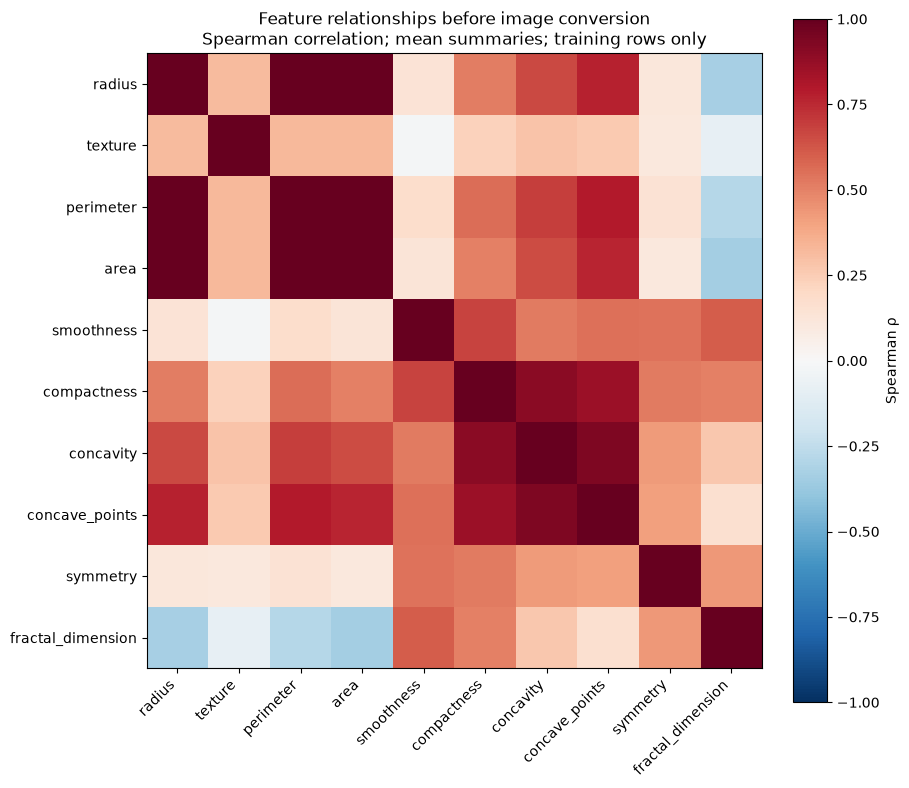

In [3]:
display(pd.DataFrame(report['training_top_absolute_spearman_pairs']))
figure = correlation_figure(frame, splits)
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## 3. One row becomes one numeric image
Our fixed grid places features in source order, row by row. This is arbitrary placement, not a learned neighborhood. A scaler fitted on training rows changes units; the grid itself only changes positions. We keep float64 values, with no clipping or conversion to an 8-bit image. Held-out values may fall outside [0, 1].

Follow radius_mean, perimeter_mean, and area_mean. The full mapping below records every original field's location. Colors describe values, not explanations.

,feature,feature_index,row,column,raw_value,scaled_value,decoded_raw_value
0,radius_mean,0,0,0,17.99,0.543950,17.99
2,perimeter_mean,2,0,2,122.80,0.571253,122.80
3,area_mean,3,0,3,1001.00,0.407073,1001.00


,feature,feature_index,row,column,raw_value,scaled_value,decoded_raw_value
0,radius_mean,0,0,0,17.990000,0.543950,17.990000
1,texture_mean,1,0,1,10.380000,0.000000,10.380000
2,perimeter_mean,2,0,2,122.800000,0.571253,122.800000
3,area_mean,3,0,3,1001.000000,0.407073,1001.000000
4,smoothness_mean,4,0,4,0.118400,0.593753,0.118400
5,compactness_mean,5,0,5,0.277600,0.792037,0.277600
6,concavity_mean,6,1,0,0.300100,0.703140,0.300100
7,concave_points_mean,7,1,1,0.147100,0.731113,0.147100
8,symmetry_mean,8,1,2,0.241900,0.686364,0.241900
9,fractal_dimension_mean,9,1,3,0.078710,0.634141,0.078710


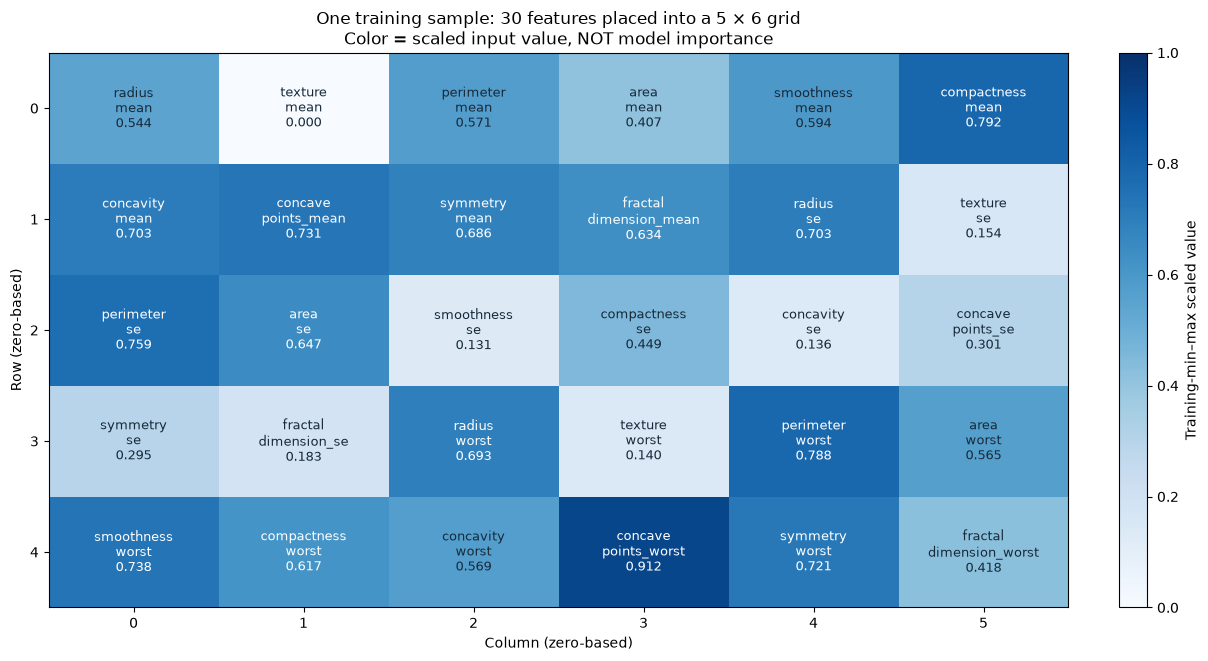

In [4]:
trace, image = trace_example(frame, splits, scaler, mapping)
display(trace[trace['feature'].isin(['radius_mean', 'perimeter_mean', 'area_mean'])])
display(trace)
figure = encoding_figure(image, mapping)
display(figure)
plt.close(figure)

## 4. Verify what conversion preserved
The numerical image must decode exactly to the scaled values. Inverse scaling should recover the raw numeric values within floating-point tolerance. These checks cover all partitions; they are mechanical integrity checks, not evaluation of prediction performance.

The PNG visualization is only a display. It is never loaded as a model input or used for the round-trip check.

In [5]:
display(pd.DataFrame({name: {key: value for key, value in part.items() if key.endswith('error')} for name, part in report['splits'].items()}).T)
assert all(part['scaled_round_trip_max_abs_error'] == 0 for part in report['splits'].values())
assert report['encoding']['occupied_pixels'] == 30
assert report['encoding']['collisions'] == 0
assert report['encoding']['padding_pixels'] == 0
np.testing.assert_array_equal(scaler.data_min_, frame.iloc[splits['train']][list(FEATURES)].min().to_numpy())
print('30/30 features preserved; training-only scaling verified; no classifier trained.')

,scaled_round_trip_max_abs_error,raw_round_trip_max_abs_error
train,0.0,4.547474e-13
validation,0.0,4.547474e-13
test,0.0,4.547474e-13


30/30 features preserved; training-only scaling verified; no classifier trained.


## Reflection and next experiment
1. Explain what the target, ID, and each of the three feature-summary blocks mean.
2. Explain why pixel brightness is not feature importance.
3. Explain why nearby pixels in this fixed grid need not be statistically similar.
4. Explain why recoverable values do not prove useful explanations.

SOM2IMG differs by learning feature placement from profiles across samples. Its collision policy and exact implementation still need verification; see [our manuscript review](../../week02/SOM2IMG_REVIEW.md). The next experiment is simple tabular baselines plus a small fixed-grid CNN using the recorded split. Model and explanation comparisons have not been run. Genomic dataset work remains preserved for later.